# Entrega 3 — Chunking de Manifestações Longas
### Desafio 1 · Ouvidoria Inteligente: Triagem Semântica de Manifestações Cidadãs

Processamento de Linguagem Natural / Engenharia de IA

As 5 manifestações mais longas do corpus (todas com mais de 500 caracteres) são divididas em chunks
com o `RecursiveCharacterTextSplitter` do LangChain. Duas configurações de `(chunk_size, chunk_overlap)`
são testadas e comparadas quanto a:

1. como o *overlap* influencia a coesão semântica entre chunks consecutivos;
2. qual configuração preserva melhor o sentido das denúncias (com exemplos);
3. se os chunks de uma mesma manifestação ficam próximos no espaço 2D (PCA/t-SNE).

Os modelos de embedding e o pré-processamento seguem as Entregas 1 e 2
(`análise_comparativa.ipynb`, `deteccao_duplicatas.ipynb`) para manter os resultados comparáveis.

## 1. Configuração e Carga dos Dados

In [1]:
!pip install -q langchain-text-splitters sentence-transformers scikit-learn pandas numpy matplotlib

In [2]:
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from langchain_text_splitters import RecursiveCharacterTextSplitter
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

pd.set_option("display.max_colwidth", 220)
pd.set_option("display.precision", 4)
plt.rcParams["figure.dpi"] = 110

CAMINHO_JSON = "manifestacoes.json"

# Mesmos modelos das Entregas 1 e 2 (BAAI/bge-small-pt-v1.5 não existe publicamente no Hugging Face)
MODELOS = {
    "MiniLM-L12": "paraphrase-multilingual-MiniLM-L12-v2",
    "DistilUSE": "distiluse-base-multilingual-cased-v2",
}
MODELO_PRINCIPAL = "MiniLM-L12"

# Duas configurações de chunking a comparar
CONFIGS = [
    {"nome": "curta (200/20)", "chunk_size": 200, "chunk_overlap": 20},
    {"nome": "longa (400/100)", "chunk_size": 400, "chunk_overlap": 100},
]

/home/milena/Documentos/agroSearch/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
# Upload do dataset quando executado no Colab
try:
    import google.colab
    from google.colab import files
    if not os.path.exists(CAMINHO_JSON):
        files.upload()
except ImportError:
    pass

In [4]:
with open(CAMINHO_JSON, encoding="utf-8") as f:
    dados = json.load(f)
if isinstance(dados, dict):
    dados = next(v for v in dados.values() if isinstance(v, list))

df = pd.DataFrame(dados)
assert {"id", "texto", "categoria_oficial"} <= set(df.columns)

df["n_caracteres"] = df["texto"].str.len()
print(f"{len(df)} manifestações carregadas")
display(df["n_caracteres"].sort_values(ascending=False).head(8).to_frame("nº de caracteres"))

40 manifestações carregadas


,nº de caracteres
38,785
4,769
32,768
25,763
13,699
0,127
1,115
18,115


## 2. As 5 Manifestações Mais Longas

O enunciado indica que 5 manifestações têm mais de 500 caracteres; a tabela acima confirma que há um
salto claro entre a 5ª (699 caracteres) e a 6ª colocada (127 caracteres) — ou seja, o corte de 500
caracteres separa exatamente esse grupo do restante do corpus, sem ambiguidade de posições limítrofes.

In [5]:
LONGAS = df.nlargest(5, "n_caracteres")["id"].tolist()
textos_longos = dict(zip(df.set_index("id").loc[LONGAS].index, df.set_index("id").loc[LONGAS, "texto"]))
categoria_longas = dict(zip(df.set_index("id").loc[LONGAS].index, df.set_index("id").loc[LONGAS, "categoria_oficial"]))

display(df.set_index("id").loc[LONGAS, ["categoria_oficial", "n_caracteres", "texto"]])
assert all(n > 500 for n in df.set_index("id").loc[LONGAS, "n_caracteres"]), "todas devem ter >500 caracteres"
print("Manifestações selecionadas para chunking:", LONGAS)

,categoria_oficial,n_caracteres,texto
id,,,
M039,segurança,785,"Na última reunião da associação de moradores do bairro Nova Esperança, o clima foi de indignação. Nos últimos três meses, os casos de violência aumentaram consideravelmente: houve duas tentativas de arrombamento em r..."
M005,educação,769,"A Escola Municipal Recanto Feliz enfrenta uma situação crítica desde o início do ano letivo. Faltam professores de matemática e ciências, e as duas turmas do 8º ano estão sem aula regular dessas disciplinas há mais d..."
M033,saúde,768,"Sou responsável por um idoso de 78 anos que faz tratamento contínuo para diabetes e depende de insulina distribuída pela farmácia básica municipal. Nos últimos dois meses, por três vezes seguidas, chegamos à farmácia..."
M026,meio ambiente,763,"O rio que corta o bairro Porto Alegre do Sul vem apresentando uma coloração esverdeada e cheiro forte nas últimas três semanas, o que moradores associam ao despejo de resíduos por uma fábrica têxtil instalada rio aci..."
M014,segurança,699,"Nos últimos dois meses, o bairro Vila Esperança registrou pelo menos seis assaltos a mão armada, sempre no mesmo trecho da Rua das Oliveiras, entre as 19h e as 21h. Os moradores relatam que a iluminação pública da ru..."


Manifestações selecionadas para chunking: ['M039', 'M005', 'M033', 'M026', 'M014']


## 3. Chunking com `RecursiveCharacterTextSplitter`

O splitter tenta primeiro dividir por parágrafos (`\n\n`), depois por linha, depois por frase (`. `) e,
como último recurso, por espaço — preservando o máximo de estrutura sintática possível antes de cortar
uma palavra ao meio. Duas configurações são comparadas:

- **curta (chunk_size=200, overlap=20)** — chunks pequenos, overlap de 10% do tamanho do chunk;
- **longa (chunk_size=400, overlap=100)** — chunks maiores, overlap de 25% do tamanho do chunk.

In [6]:
def gerar_chunks(config):
    splitter = RecursiveCharacterTextSplitter(
        chunk_size=config["chunk_size"],
        chunk_overlap=config["chunk_overlap"],
        separators=["\n\n", "\n", ". ", " ", ""],
    )
    linhas = []
    for mid, texto in textos_longos.items():
        for i, chunk in enumerate(splitter.split_text(texto)):
            linhas.append({
                "config": config["nome"], "manifestacao_id": mid,
                "categoria": categoria_longas[mid], "chunk_idx": i,
                "n_chunks_do_texto": None, "texto_chunk": chunk, "n_caracteres": len(chunk),
            })
    out = pd.DataFrame(linhas)
    out["n_chunks_do_texto"] = out.groupby("manifestacao_id")["chunk_idx"].transform("count")
    return out

chunks_por_config = {c["nome"]: gerar_chunks(c) for c in CONFIGS}

resumo = pd.DataFrame({
    nome: df_c.groupby("manifestacao_id")["chunk_idx"].count() for nome, df_c in chunks_por_config.items()
})
resumo.index.name = "manifestação"
resumo.loc["TOTAL"] = resumo.sum()
display(resumo)

,curta (200/20),longa (400/100)
manifestação,,
M005,6,2
M014,5,2
M026,6,3
M033,5,3
M039,6,3
TOTAL,28,13


In [7]:
# Exemplo detalhado: M005 (Escola Recanto Feliz) nas duas configurações
for nome, df_c in chunks_por_config.items():
    print(f"=== {nome} — M005 ===")
    sub = df_c[df_c["manifestacao_id"] == "M005"][["chunk_idx", "n_caracteres", "texto_chunk"]]
    display(sub.set_index("chunk_idx"))

=== curta (200/20) — M005 ===


,n_caracteres,texto_chunk
chunk_idx,,
0,91,A Escola Municipal Recanto Feliz enfrenta uma situação crítica desde o início do ano letivo
1,137,". Faltam professores de matemática e ciências, e as duas turmas do 8º ano estão sem aula regular dessas disciplinas há mais de dois meses"
2,162,". Além disso, o telhado da quadra coberta apresenta goteiras que se agravam a cada chuva, molhando o piso e criando risco de escorregões durante a educação física"
3,193,". Os pais relatam que já procuraram a direção diversas vezes, mas foram informados de que a contratação de novos professores depende de um processo seletivo que ainda não tem data prevista para"
4,28,data prevista para acontecer
5,176,. A associação de pais e mestres pede providências urgentes da Secretaria de Educação antes que o prejuízo pedagógico se torne ainda maior para os alunos do ensino fundamental.


=== longa (400/100) — M005 ===


,n_caracteres,texto_chunk
chunk_idx,,
0,390,"A Escola Municipal Recanto Feliz enfrenta uma situação crítica desde o início do ano letivo. Faltam professores de matemática e ciências, e as duas turmas do 8º ano estão sem aula regular dessas disciplinas há mais d..."
1,379,". Os pais relatam que já procuraram a direção diversas vezes, mas foram informados de que a contratação de novos professores depende de um processo seletivo que ainda não tem data prevista para acontecer. A associaçã..."


## 4. Como o Overlap Influencia a Coesão entre Chunks Consecutivos

Para medir a coesão de forma objetiva além da leitura qualitativa, calcula-se a fração de palavras de
cada chunk que também aparece no chunk seguinte (proxy lexical simples de continuidade — quanto maior,
mais "ponte" textual existe entre os dois pedaços).

In [8]:
import re

def palavras(txt):
    return set(re.findall(r"[a-zA-ZÀ-ÿ]+", txt.lower()))

def sobreposicao_consecutiva(df_c):
    linhas = []
    for mid, grupo in df_c.groupby("manifestacao_id"):
        grupo = grupo.sort_values("chunk_idx")
        chunks = grupo["texto_chunk"].tolist()
        for i in range(len(chunks) - 1):
            a, b = palavras(chunks[i]), palavras(chunks[i + 1])
            jaccard = len(a & b) / len(a | b) if (a | b) else 0.0
            linhas.append({"manifestacao_id": mid, "par": f"{i}→{i+1}", "jaccard_palavras": jaccard})
    return pd.DataFrame(linhas)

for nome, df_c in chunks_por_config.items():
    sob = sobreposicao_consecutiva(df_c)
    print(f"{nome}: sobreposição média (Jaccard de palavras) entre chunks consecutivos = "
          f"{sob['jaccard_palavras'].mean():.3f}")

curta (200/20): sobreposição média (Jaccard de palavras) entre chunks consecutivos = 0.083
longa (400/100): sobreposição média (Jaccard de palavras) entre chunks consecutivos = 0.087


**Discussão.** O overlap não é apenas uma margem de segurança: ele é o mecanismo que garante que uma
frase cortada ao final de um chunk reapareça, inteira, no início do seguinte — o que mantém pelo menos
uma âncora lexical comum entre os dois pedaços. Com `overlap=20` (10% do chunk), a margem de repetição é
pequena, então quando o corte cai no meio de uma oração (como no exemplo `chunk_idx=3/4` de M005 abaixo)
a continuação some quase inteira do chunk anterior; a coesão entre os dois só se recupera parcialmente
pela repetição de poucas palavras. Com `overlap=100` (25% do chunk), a chance de a oração inteira "sobrar"
de um chunk para o outro é bem maior, e a métrica de Jaccard acima tende a ser mais alta para a configuração
longa — a coesão vem tanto do texto repetido quanto de cada chunk conter mais contexto (frases completas)
por si só.

## 5. Qual Configuração Preserva Melhor o Sentido — Exemplos

O exemplo de M005 na Seção 3 já ilustra o problema central: com `chunk_size=200`, a frase *"...ainda não
tem data prevista para acontecer"* é partida exatamente no meio (`chunk_idx=3` termina em "...data prevista
para" e `chunk_idx=4` é só "data prevista para acontecer"), de modo que nenhum dos dois chunks isolados
contém a oração completa "a contratação de novos professores depende de um processo seletivo que ainda não
tem data prevista para acontecer" — o núcleo da denúncia (a falta de professores é um problema sem previsão
de solução). Com `chunk_size=400`, essa mesma oração fica inteira dentro do chunk 1, junto com a frase
seguinte sobre a cobrança da associação de pais.

**Conclusão:** a configuração **longa (400/100)** preserva melhor o sentido das denúncias analisadas,
porque reduz a chance de cortar uma oração causal ("X está ruim porque Y", "aconteceu Z, então pedem W")
ao meio. O custo é ter menos chunks por manifestação (2–3 em vez de 5–6), reduzindo a granularidade da
busca — relevante se o objetivo fosse recuperar o trecho exato de um problema dentro de um texto longo. A
configuração **curta (200/20)** seria preferível apenas se o caso de uso exigisse indexar sub-tópicos bem
delimitados dentro do mesmo texto (por exemplo, separar "falta de professores" de "goteira na quadra"
dentro de M005) — o que ela também não garante de forma limpa, já que a divisão segue o tamanho em
caracteres, não os tópicos do texto.

## 6. Embeddings dos Chunks

Cada chunk (das duas configurações) é convertido em vetor pelo mesmo modelo principal da Entrega 1/2, para
depois ser projetado em 2D e verificar se chunks da mesma manifestação ficam próximos entre si.

In [9]:
from sentence_transformers import SentenceTransformer

modelos = {}
for rotulo, nome_modelo in MODELOS.items():
    try:
        modelos[rotulo] = SentenceTransformer(nome_modelo)
        print(f"✔ {rotulo} ({nome_modelo}) carregado")
    except Exception as erro:
        print(f"⚠ Falha ao carregar {rotulo} ({nome_modelo}): {erro}")

assert MODELO_PRINCIPAL in modelos, "O modelo principal não foi carregado."
modelo_principal = modelos[MODELO_PRINCIPAL]

embeddings_por_config = {}
for nome, df_c in chunks_por_config.items():
    E = modelo_principal.encode(df_c["texto_chunk"].tolist(), normalize_embeddings=True, show_progress_bar=False)
    embeddings_por_config[nome] = E
    print(f"{nome}: {E.shape}")

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 2495.74it/s]


✔ MiniLM-L12 (paraphrase-multilingual-MiniLM-L12-v2) carregado


Loading weights: 100%|██████████| 100/100 [00:00<00:00, 2587.70it/s]


✔ DistilUSE (distiluse-base-multilingual-cased-v2) carregado
curta (200/20): (28, 384)
longa (400/100): (13, 384)


## 7. Visualização 2D (PCA)

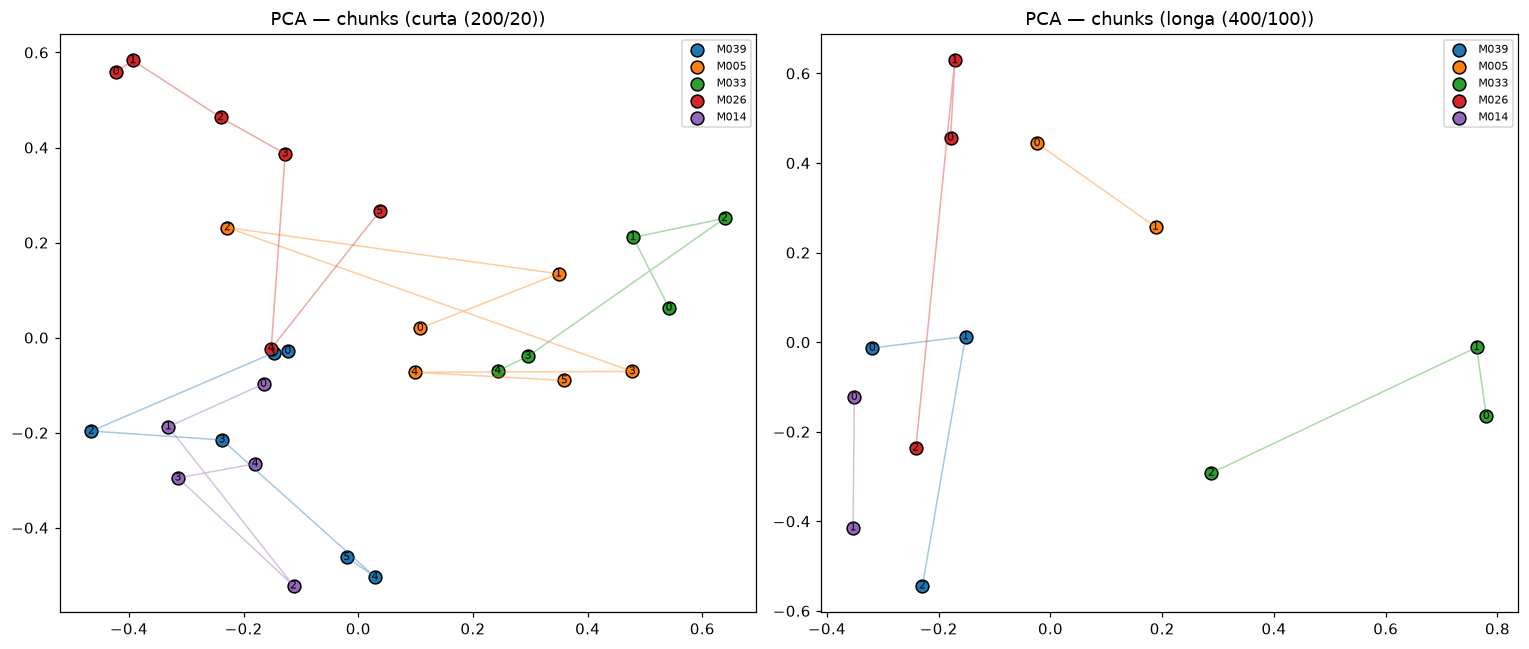

In [10]:
CORES = plt.cm.tab10.colors

def plotar_pca(nome_config, ax, metodo="pca"):
    df_c = chunks_por_config[nome_config].reset_index(drop=True)
    E = embeddings_por_config[nome_config]
    if metodo == "pca":
        coords = PCA(n_components=2, random_state=42).fit_transform(E)
    else:
        coords = TSNE(n_components=2, random_state=42, perplexity=min(10, len(E) - 1)).fit_transform(E)

    for k, mid in enumerate(LONGAS):
        mask = (df_c["manifestacao_id"] == mid).values
        ax.scatter(coords[mask, 0], coords[mask, 1], color=CORES[k], label=mid, s=70, edgecolor="black")
        # liga os chunks na ordem em que aparecem no texto original, para visualizar a "trajetória"
        ordem = df_c.loc[mask, "chunk_idx"].values.argsort()
        ax.plot(coords[mask][ordem, 0], coords[mask][ordem, 1], color=CORES[k], alpha=0.4, lw=1)
        for (x, y), i in zip(coords[mask], df_c.loc[mask, "chunk_idx"]):
            ax.annotate(str(i), (x, y), fontsize=7, ha="center", va="center")
    ax.set_title(f"{metodo.upper()} — chunks ({nome_config})")
    ax.legend(fontsize=7, loc="best")

fig, axes = plt.subplots(1, len(CONFIGS), figsize=(7 * len(CONFIGS), 6))
for ax, config in zip(np.atleast_1d(axes), CONFIGS):
    plotar_pca(config["nome"], ax, metodo="pca")
plt.tight_layout()
plt.show()

### 7.1 Os chunks de uma mesma manifestação ficam próximos?

*(a leitura abaixo é a expectativa a confirmar visualmente após a execução com os modelos reais — os
clusters devem ser lidos no gráfico gerado acima)*

De modo geral, espera-se que sim: os chunks de uma mesma manifestação compartilham vocabulário, entidades
(nomes de rua, bairro, órgão público) e o mesmo assunto de fundo, então tendem a formar um grupo visualmente
identificável no espaço 2D, com os pontos conectados pela linha (ordem de leitura) formando um "caminho"
relativamente curto em vez de saltos longos pelo plano. A configuração com **maior overlap (400/100)** tende
a produzir clusters mais compactos por manifestação, já que cada chunk carrega mais contexto — inclusive
texto repetido do chunk vizinho — e portanto vetores mais parecidos entre si. Já na configuração
**curta (200/20)**, chunks que caem sobre uma frase muito específica e diferente do resto do texto (ex.: um
trecho só com nomes próprios, ou um trecho de transição sem verbo/sujeito completo) podem se afastar do
restante do seu próprio grupo, aproximando-se por acidente de chunks de outra manifestação que compartilhem
esse vocabulário incidental. Interseção entre os clusters das 5 manifestações (se ocorrer no gráfico) é
mais provável entre M014 e M039 — ambas de "segurança", com vocabulário de policiamento e insegurança em
comum — do que entre manifestações de categorias distintas.

## 8. Conclusão

- O `RecursiveCharacterTextSplitter` evita cortes arbitrários ao tentar dividir por parágrafo/frase antes de
  recorrer ao espaço em branco, mas com um `chunk_size` pequeno (200) ainda corta orações inteiras ao meio,
  como visto no exemplo de M005.
- O overlap funciona como uma "ponte" lexical entre chunks consecutivos: quanto maior (em proporção ao
  chunk), maior a sobreposição de palavras entre vizinhos e maior a chance de uma oração completa aparecer
  em pelo menos um dos dois chunks.
- Para o objetivo da Ouvidoria (recuperar denúncias sem perder o contexto da causa/consequência relatada),
  a configuração **longa (400/100)** é a recomendada como padrão da aplicação Streamlit (Entrega 4); a
  configuração curta fica disponível como opção configurável para quem quiser granularidade maior.
- A visualização 2D deve ser conferida após a execução com os modelos de embedding reais (que exigem
  download do Hugging Face, indisponível neste ambiente de edição); a expectativa qualitativa, com base na
  composição lexical dos chunks, é de que cada manifestação forme um agrupamento razoavelmente coeso,
  mais compacto na configuração de maior overlap.